**Re-run note (2026-10-15).** The data (UCI banknote authentication) is downloaded in the second cell and is unchanged; the earlier outputs of this notebook were stored from an older run and have been refreshed. To make the notebook run top to bottom on current libraries: `model1.add(Dense())` (a layer without units) was removed, `Input` is now imported, the later cells that used the undefined names `y_pred2`, `y_class2` now use `y_pred21` and `y_class21`, and `ann_visualizer` (needs the graphviz program) was replaced by a short matplotlib function with the same name. Training is not seeded, so numbers change slightly on each run.

In [1]:
import pandas as pd
import numpy as np


In [2]:
import os, urllib.request
os.makedirs("data", exist_ok=True)
BANKNOTE_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"
BANKNOTE_PATH = "data/data_banknote_authentication.txt"
if not os.path.exists(BANKNOTE_PATH):
    urllib.request.urlretrieve(BANKNOTE_URL, BANKNOTE_PATH)
# UCI file has no header row; these are the column names of the Kaggle copy the notebook was written for.
df = pd.read_csv(BANKNOTE_PATH, header=None, names=["variance", "skewness", "curtosis", "entropy", "class"])

In [3]:
df.head()

,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [4]:
df.tail()

,variance,skewness,curtosis,entropy,class
1367,0.40614,1.34920,-1.4501,-0.55949,1
1368,-1.38870,-4.87730,6.4774,0.34179,1
1369,-3.75030,-13.45860,17.5932,-2.77710,1
1370,-3.56370,-8.38270,12.3930,-1.28230,1
1371,-2.54190,-0.65804,2.6842,1.19520,1


In [5]:
df.isnull().sum()

variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


In [7]:
df['class'].unique

<bound method Series.unique of 0       0
1       0
2       0
3       0
4       0
       ..
1367    1
1368    1
1369    1
1370    1
1371    1
Name: class, Length: 1372, dtype: int64>

In [8]:
df['class'].value_counts()

class
0    762
1    610
Name: count, dtype: int64

In [9]:
df.shape


(1372, 5)

In [10]:
df.columns

Index(['variance', 'skewness', 'curtosis', 'entropy', 'class'], dtype='object')

In [11]:
df['class'].value_counts(normalize= True)*100

class
0    55.539359
1    44.460641
Name: proportion, dtype: float64

In [12]:
x = df.drop('class', axis = 1)
y = df['class']

In [13]:
x.shape

(1372, 4)

In [14]:
y.shape

(1372,)

In [15]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.25, random_state =42)

In [16]:
import tensorflow as tf


In [17]:
print(tf.__version__)

2.15.1


In [18]:
from tensorflow.keras.models import Sequential

In [19]:
from tensorflow.keras.layers import Dense , InputLayer , Dropout, Input

In [20]:
model1 = Sequential()
model1.add(Dense(6, input_shape = (4,),kernel_initializer='he_uniform',activation='relu'))
model1.add(Dense(1, activation='sigmoid'))


In [21]:
model1.summary()

Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 dense (Dense)               (None, 6)                 30        


 dense_1 (Dense)             (None, 1)                 7         


Total params: 37 (148.00 Byte)


Trainable params: 37 (148.00 Byte)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


In [22]:
model1.compile(optimizer="sgd",
              loss= "binary_crossentropy",
              metrics=["accuracy"])


In [23]:
model1.get_weights()

[array([[-0.44657904, -0.6240204 , -0.6967867 , -0.9960087 ,  0.26696038,
         -0.44778758],
        [ 0.12646139, -1.221541  ,  0.8620447 ,  0.5716145 ,  0.5228497 ,
         -0.25494748],
        [ 0.3636905 ,  0.0412184 , -0.8595693 , -0.6064115 , -1.2137344 ,
         -0.43577933],
        [-0.83771706,  0.5765976 , -0.33379674,  1.0176493 , -0.10844803,
         -0.22566992]], dtype=float32),
 array([0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[ 0.6363634 ],
        [ 0.9237412 ],
        [-0.8279362 ],
        [-0.3345332 ],
        [ 0.32403672],
        [ 0.20566595]], dtype=float32),
 array([0.], dtype=float32)]

In [24]:
model1.fit(x_train, y_train, epochs= 10)

Epoch 1/10


 1/33 [..............................] - ETA: 26s - loss: 1.5675 - accuracy: 0.4375

33/33 [==============================] - 1s 2ms/step - loss: 0.8545 - accuracy: 0.5811


Epoch 2/10


 1/33 [..............................] - ETA: 0s - loss: 0.6116 - accuracy: 0.7188

...

 1/33 [..............................] - ETA: 0s - loss: 0.3231 - accuracy: 0.9375

33/33 [==============================] - 0s 1ms/step - loss: 0.2468 - accuracy: 0.9495


Epoch 10/10


 1/33 [..............................] - ETA: 0s - loss: 0.2259 - accuracy: 0.9375

33/33 [==============================] - 0s 1ms/step - loss: 0.2354 - accuracy: 0.9543


In [25]:
model1.evaluate(x_test,y_test)

 1/11 [=>............................] - ETA: 2s - loss: 0.2203 - accuracy: 0.9688

11/11 [==============================] - 0s 2ms/step - loss: 0.2372 - accuracy: 0.9621


[0.23717612028121948, 0.9620991349220276]

In [26]:
model1.get_weights()

[array([[-0.7530561 , -0.87169963, -0.27194488, -0.9380949 ,  0.01995953,
         -0.54865116],
        [ 0.07708774, -0.84587413,  1.1459205 ,  0.5603897 ,  0.35162276,
         -0.14355986],
        [-0.13521187, -0.41180572, -0.63026786, -0.57209027, -1.3335645 ,
         -0.56010824],
        [-0.8382959 ,  0.6310588 , -0.27981862,  1.0459181 , -0.13770905,
         -0.29154432]], dtype=float32),
 array([ 0.04680492, -0.03535243, -0.0541956 , -0.02018744,  0.02447327,
         0.08143178], dtype=float32),
 array([[ 0.8055252 ],
        [ 0.82392555],
        [-0.6884566 ],
        [ 0.07882367],
        [ 0.44520912],
        [ 0.5127018 ]], dtype=float32),
 array([-0.25801715], dtype=float32)]

In [27]:
y_predict1 = model1.predict(x_test)

 1/11 [=>............................] - ETA: 1s

11/11 [==============================] - 0s 1ms/step


In [28]:
y_predict1.shape

(343, 1)

In [29]:
y_pred1 = y_predict1.flatten()

In [30]:
y_pred1.shape

(343,)

In [31]:
a= np.arange(1,10).reshape(3,3)

In [32]:
a

array([[1, 2, 3],
       [4, 5, 6],
       [7, 8, 9]])

In [33]:
a=a.flatten()
a

array([1, 2, 3, 4, 5, 6, 7, 8, 9])

In [34]:
y_pred1

array([0.0441285 , 0.1975188 , 0.22418785, 0.0131425 , 0.00999237,
       0.4358512 , 0.01445033, 0.20925026, 0.4358512 , 0.02818673,
       0.44784594, 0.75183356, 0.4358512 , 0.96903163, 0.4358512 ,
       0.65370196, 0.8165565 , 0.8200199 , 0.9962713 , 0.73218495,
       0.01603954, 0.4358512 , 0.87569064, 0.00809548, 0.8340344 ,
       0.05317334, 0.02363827, 0.9667726 , 0.00909599, 0.01652136,
       0.93223757, 0.42753103, 0.4358512 , 0.83928514, 0.8655782 ,
       0.01308535, 0.41099933, 0.79134357, 0.8116412 , 0.22398403,
       0.4358512 , 0.9271057 , 0.630532  , 0.01653869, 0.9727952 ,
       0.98489946, 0.9137312 , 0.4358512 , 0.4358512 , 0.72916603,
       0.4358512 , 0.21159422, 0.04847049, 0.02132948, 0.02384984,
       0.5734211 , 0.24972095, 0.02016986, 0.4358512 , 0.01232909,
       0.9765552 , 0.29965195, 0.96478134, 0.01180105, 0.02275517,
       0.02332551, 0.15166803, 0.02022038, 0.5723042 , 0.9759553 ,
       0.94103146, 0.02881468, 0.9830846 , 0.11370263, 0.88886

In [35]:
y_class1 = (y_pred1>0.5).astype(int)
from sklearn.metrics import confusion_matrix, accuracy_score
confusion_matrix (y_test, y_class1)


array([[185,   6],
       [  7, 145]], dtype=int64)

In [36]:
accuracy_score (y_test, y_class1)

0.9620991253644315

In [37]:
model21 = Sequential()
model21.add(Dense(6, input_shape = (4,),kernel_initializer='he_uniform',activation='relu'))
model21.add(Dropout(rate = 0.2))
model21.add(Dense(1, activation='sigmoid'))
model21.summary()

Model: "sequential_1"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 dense_2 (Dense)             (None, 6)                 30        


 dropout (Dropout)           (None, 6)                 0         


 dense_3 (Dense)             (None, 1)                 7         


Total params: 37 (148.00 Byte)


Trainable params: 37 (148.00 Byte)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


In [38]:
model21.get_weights()

[array([[-0.69450617,  0.23987699,  0.01988709, -0.65541357,  0.31466627,
          0.70018184],
        [ 0.12490618, -0.98485017, -0.92590195,  1.1732963 , -1.028481  ,
         -0.34187382],
        [-0.7798735 ,  0.87665   , -0.5420864 ,  0.42524302, -0.0940448 ,
          0.9547061 ],
        [ 0.3411181 , -0.7010219 , -0.08299077,  0.50772417, -1.0160768 ,
          0.00396776]], dtype=float32),
 array([0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-0.5133431 ],
        [ 0.3187667 ],
        [ 0.77490556],
        [ 0.03896946],
        [-0.5067882 ],
        [-0.9118411 ]], dtype=float32),
 array([0.], dtype=float32)]

In [39]:
model21.compile(optimizer="sgd",
              loss= "binary_crossentropy",
              metrics=["accuracy"])
model21.fit(x_train, y_train, epochs= 10)

Epoch 1/10


 1/33 [..............................] - ETA: 18s - loss: 1.5201 - accuracy: 0.4062

33/33 [==============================] - 1s 1ms/step - loss: 0.9733 - accuracy: 0.6142


Epoch 2/10


 1/33 [..............................] - ETA: 0s - loss: 0.7675 - accuracy: 0.6875

...

 1/33 [..............................] - ETA: 0s - loss: 0.2853 - accuracy: 0.8438

33/33 [==============================] - 0s 1ms/step - loss: 0.3220 - accuracy: 0.8260


Epoch 10/10


 1/33 [..............................] - ETA: 0s - loss: 0.4470 - accuracy: 0.8125

33/33 [==============================] - 0s 1ms/step - loss: 0.3169 - accuracy: 0.8309


In [40]:
model21.evaluate(x_test,y_test)

 1/11 [=>............................] - ETA: 1s - loss: 0.1862 - accuracy: 0.9062

11/11 [==============================] - 0s 2ms/step - loss: 0.2381 - accuracy: 0.9242


[0.2381400465965271, 0.9241982698440552]

In [41]:
y_predict21 = model21.predict(x_test)
y_pred21 = y_predict21.flatten()
y_class21 = (y_pred21>0.5).astype(int)



 1/11 [=>............................] - ETA: 0s

11/11 [==============================] - 0s 1ms/step


In [42]:
accuracy_score (y_test, y_class21)

0.924198250728863

In [43]:


confusion_matrix (y_test, y_class21)


array([[189,   2],
       [ 24, 128]], dtype=int64)

In [44]:
y_class21.shape

(343,)

In [45]:
confusion_matrix (y_test, y_class21)

array([[189,   2],
       [ 24, 128]], dtype=int64)

In [46]:
# ann_visualizer (a 2018 package) needs the graphviz program, which is not installed everywhere,
# so the network diagram is drawn here with matplotlib instead. The function keeps the old name.
import matplotlib.pyplot as plt

def ann_viz(model, title="ANN", max_nodes=10):
    """Draw the Dense layers of a Sequential model as columns of nodes (Dropout layers are skipped)."""
    sizes = [model.input_shape[-1]] + [l.units for l in model.layers if isinstance(l, Dense)]
    labels = ["input"] + ["dense %d" % (i + 1) for i in range(len(sizes) - 1)]
    fig, ax = plt.subplots(figsize=(2 + 1.6 * len(sizes), 5))
    xs, ys = [], []
    for k, n in enumerate(sizes):
        shown = min(n, max_nodes)
        y = [(shown - 1) / 2 - j for j in range(shown)]
        xs.append([k] * shown)
        ys.append(y)
        ax.scatter([k] * shown, y, s=250, zorder=3, color="tab:blue" if k < len(sizes) - 1 else "tab:green")
        ax.text(k, (max_nodes + 1) / 2 + 0.4, "%s\n(%d)" % (labels[k], n), ha="center")
    for k in range(len(sizes) - 1):
        for y0 in ys[k]:
            for y1 in ys[k + 1]:
                ax.plot([k, k + 1], [y0, y1], color="gray", lw=0.4, zorder=1)
    ax.set_title(title + " (at most %d nodes drawn per layer)" % max_nodes)
    ax.axis("off")
    plt.show()

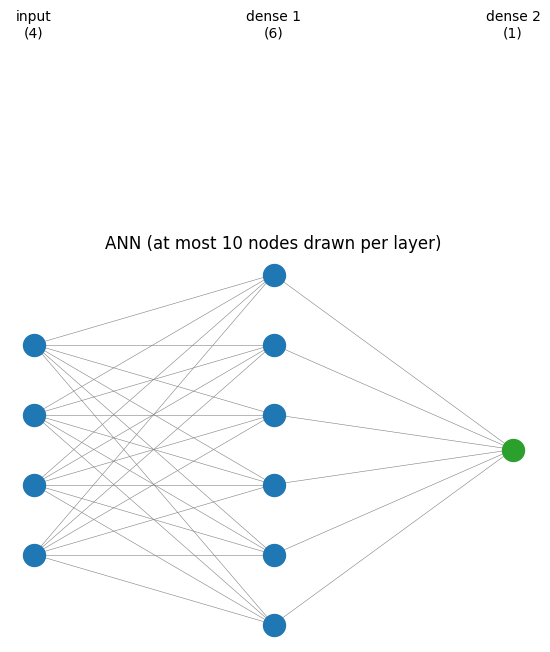

In [47]:
ann_viz(model1, title = "ANN")

In [48]:
model2 = Sequential()
model2.add(Dense(64, input_shape = (4,), activation='relu'))
model2.add(Dense(32,  activation='relu'))
model2.add(Dense(16,  activation='relu'))
model2.add(Dense(8,  activation='relu'))
model2.add(Dense(1,activation='sigmoid'))

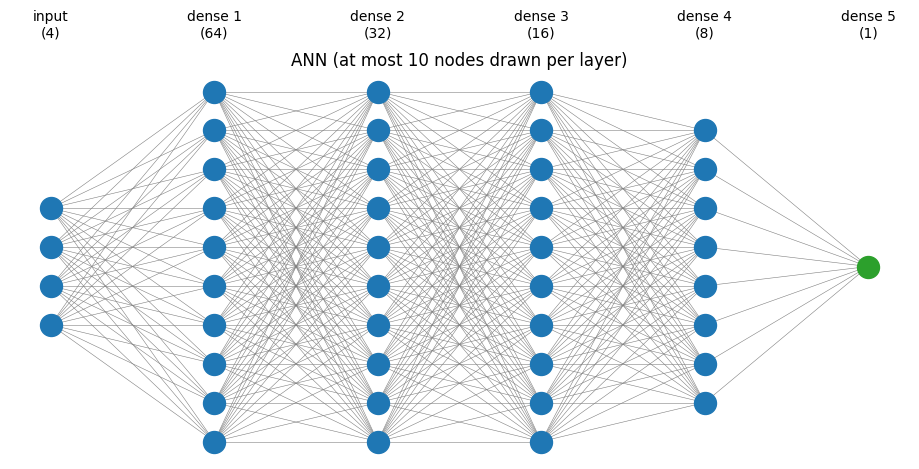

In [49]:
ann_viz(model2, title = "ANN")

In [50]:
model2.summary()

Model: "sequential_2"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 dense_4 (Dense)             (None, 64)                320       


 dense_5 (Dense)             (None, 32)                2080      


...

 dense_8 (Dense)             (None, 1)                 9         


Total params: 3073 (12.00 KB)


Trainable params: 3073 (12.00 KB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


In [51]:
model2.get_weights()

[array([[ 1.89814031e-01, -1.04314968e-01,  1.37382567e-01,
         -4.46496606e-02, -2.55138218e-01, -2.80131817e-01,
          7.21058547e-02,  2.05853045e-01, -2.49657184e-01,
         -1.25858963e-01, -4.57993746e-02,  8.70467722e-02,
          1.85868382e-01, -1.18763134e-01, -2.63544023e-01,
          2.84688175e-01,  2.83027709e-01,  4.12935317e-02,
          6.10615313e-02,  2.28674650e-01,  2.52670228e-01,
          3.58060300e-02, -1.66059941e-01,  2.01589197e-01,
         -1.14984989e-01,  6.97478652e-03,  4.37029898e-02,
          4.18505371e-02, -3.24532986e-02,  2.29508519e-01,
          1.04907811e-01, -1.28733933e-01,  1.34856462e-01,
          7.71936774e-02,  1.65743530e-02,  1.90602630e-01,
         -1.31986454e-01,  2.85298049e-01, -1.18598342e-01,
         -1.73882872e-01,  8.20529461e-03,  2.45664418e-01,
          1.84686184e-01,  1.96783602e-01,  1.46197021e-01,
         -1.90738961e-01,  5.96490800e-02, -6.44744039e-02,
         -1.62040353e-01,  2.83197880e-0

In [52]:
model2.compile(optimizer="adam",
              loss= "binary_crossentropy",
              metrics=["accuracy"])


In [53]:
model2.fit(x_train, y_train, epochs= 5 )

Epoch 1/5


 1/33 [..............................] - ETA: 41s - loss: 0.8696 - accuracy: 0.3750

28/33 [========================>.....] - ETA: 0s - loss: 0.5500 - accuracy: 0.7299 

33/33 [==============================] - 1s 2ms/step - loss: 0.5212 - accuracy: 0.7619


Epoch 2/5


...

 1/33 [..............................] - ETA: 0s - loss: 0.0384 - accuracy: 1.0000

33/33 [==============================] - 0s 2ms/step - loss: 0.0212 - accuracy: 0.9990


Epoch 5/5


 1/33 [..............................] - ETA: 0s - loss: 0.0194 - accuracy: 1.0000

33/33 [==============================] - 0s 2ms/step - loss: 0.0115 - accuracy: 1.0000


In [54]:
model2.get_weights()

[array([[ 0.23900372, -0.16248171,  0.13889335,  0.02229145, -0.31312084,
         -0.36242816,  0.1345177 ,  0.24279667, -0.3207927 , -0.18225703,
         -0.01861098,  0.14651044,  0.2718509 , -0.07224922, -0.34130135,
          0.27536607,  0.2898781 ,  0.10578607,  0.09426943,  0.23580542,
          0.29878142,  0.06569506, -0.22775993,  0.15820608, -0.13764597,
         -0.00832618,  0.01893002,  0.13063836,  0.01625889,  0.30284613,
          0.14910622, -0.14175282,  0.1389052 ,  0.13282193,  0.02527939,
          0.2711741 , -0.1114884 ,  0.2755585 , -0.09725441, -0.24367541,
          0.02728371,  0.244772  ,  0.26181152,  0.24886592,  0.1258678 ,
         -0.24935561,  0.0130848 , -0.03855307, -0.24927092,  0.30021968,
          0.1827933 ,  0.25811407, -0.30202144, -0.15805995,  0.17941047,
         -0.01945809, -0.1498053 ,  0.30452567, -0.00313876, -0.3688827 ,
          0.17407702, -0.13685863, -0.3094061 , -0.24132468],
        [-0.0479579 , -0.08143347,  0.20842761, -0

In [55]:
model3 = Sequential()
model3.add(Input(shape=(4,)))
model3.add(Dense(64,activation='relu'))
model3.add(Dropout(rate = 0.2))
model3.add(Dense(32,  activation='relu'))
model3.add(Dropout(rate = 0.2 ))
model3.add(Dense(16,  activation='relu'))
model3.add(Dropout(rate = 0.2 ))
model3.add(Dense(8,  activation='relu'))
model3.add(Dropout(rate = 0.2 ))
model3.add(Dense(1,activation='sigmoid'))

In [56]:
model3.summary()

Model: "sequential_3"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 dense_9 (Dense)             (None, 64)                320       


 dropout_1 (Dropout)         (None, 64)                0         


...

 dense_13 (Dense)            (None, 1)                 9         


Total params: 3073 (12.00 KB)


Trainable params: 3073 (12.00 KB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


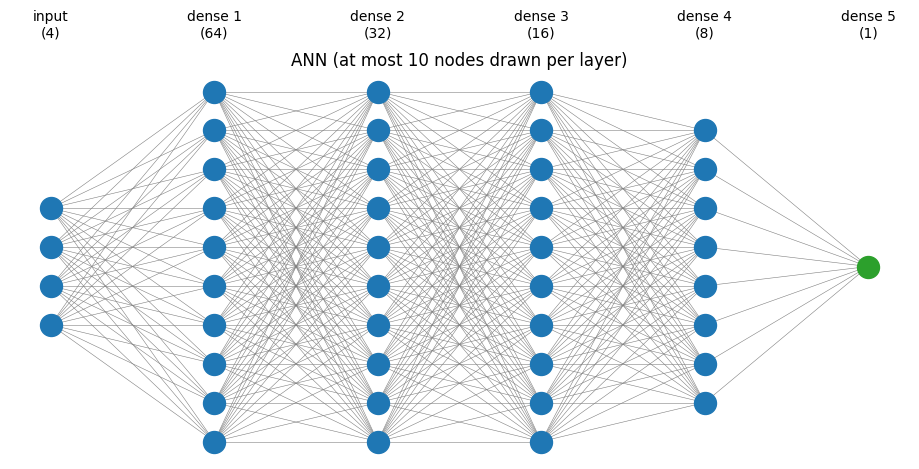

In [57]:
ann_viz(model3, title = "ANN")

In [58]:
model3.compile(optimizer="adam",
              loss= "binary_crossentropy",
              metrics=["accuracy"])


In [59]:
model3.fit(x_train, y_train, epochs= 5 )

Epoch 1/5


 1/33 [..............................] - ETA: 46s - loss: 1.2158 - accuracy: 0.4375

26/33 [======================>.......] - ETA: 0s - loss: 0.8065 - accuracy: 0.5204 

33/33 [==============================] - 2s 2ms/step - loss: 0.7701 - accuracy: 0.5569


Epoch 2/5


...

33/33 [==============================] - 0s 2ms/step - loss: 0.2728 - accuracy: 0.9135


Epoch 5/5


 1/33 [..............................] - ETA: 0s - loss: 0.2091 - accuracy: 0.9375

28/33 [========================>.....] - ETA: 0s - loss: 0.1914 - accuracy: 0.9420

33/33 [==============================] - 0s 2ms/step - loss: 0.1859 - accuracy: 0.9446


In [60]:
model3.fit(x_train, y_train, epochs= 5 )

Epoch 1/5


 1/33 [..............................] - ETA: 0s - loss: 0.2371 - accuracy: 0.9688

27/33 [=======================>......] - ETA: 0s - loss: 0.1497 - accuracy: 0.9560

33/33 [==============================] - 0s 2ms/step - loss: 0.1387 - accuracy: 0.9621


Epoch 2/5


...

33/33 [==============================] - 0s 2ms/step - loss: 0.0614 - accuracy: 0.9883


Epoch 5/5


 1/33 [..............................] - ETA: 0s - loss: 0.0802 - accuracy: 0.9688

28/33 [========================>.....] - ETA: 0s - loss: 0.0518 - accuracy: 0.9888

33/33 [==============================] - 0s 2ms/step - loss: 0.0484 - accuracy: 0.9893


In [61]:
model3.fit(x_train, y_train, epochs= 5 )

Epoch 1/5


 1/33 [..............................] - ETA: 0s - loss: 0.0423 - accuracy: 1.0000

28/33 [========================>.....] - ETA: 0s - loss: 0.0387 - accuracy: 0.9888

33/33 [==============================] - 0s 2ms/step - loss: 0.0378 - accuracy: 0.9893


Epoch 2/5


...

33/33 [==============================] - 0s 2ms/step - loss: 0.0433 - accuracy: 0.9932


Epoch 5/5


 1/33 [..............................] - ETA: 0s - loss: 0.0559 - accuracy: 1.0000

26/33 [======================>.......] - ETA: 0s - loss: 0.0281 - accuracy: 0.9976

33/33 [==============================] - 0s 2ms/step - loss: 0.0326 - accuracy: 0.9961


In [62]:
model3.fit(x_train, y_train, epochs= 5 )

Epoch 1/5


 1/33 [..............................] - ETA: 0s - loss: 0.0425 - accuracy: 1.0000

24/33 [====================>.........] - ETA: 0s - loss: 0.0365 - accuracy: 0.9948

33/33 [==============================] - 0s 2ms/step - loss: 0.0337 - accuracy: 0.9951


Epoch 2/5


...

33/33 [==============================] - 0s 2ms/step - loss: 0.0223 - accuracy: 0.9971


Epoch 5/5


 1/33 [..............................] - ETA: 0s - loss: 0.0032 - accuracy: 1.0000

29/33 [=========================>....] - ETA: 0s - loss: 0.0254 - accuracy: 0.9968

33/33 [==============================] - 0s 2ms/step - loss: 0.0275 - accuracy: 0.9971


In [63]:
y_predict = model3.predict(x_test)

 1/11 [=>............................] - ETA: 0s

11/11 [==============================] - 0s 1ms/step


In [64]:
y_predict

array([[4.38460665e-06],
       [2.14488059e-03],
       [8.13453866e-04],
       [1.00642525e-08],
       [8.21041340e-07],
       [2.07184003e-05],
       [1.00244620e-06],
       [9.36509252e-07],
       [5.12411725e-06],
       [3.92471662e-07],
       [9.99976575e-01],
       [9.99997079e-01],
       [6.69516839e-06],
       [9.99999762e-01],
       [2.35631778e-05],
       [9.99997497e-01],
       [9.99992549e-01],
       [9.99990404e-01],
       [1.00000000e+00],
       [9.99879539e-01],
       [6.27943450e-07],
       [1.99546412e-06],
       [9.99986053e-01],
       [1.59458267e-07],
       [1.00000000e+00],
       [6.48304251e-07],
       [7.51998712e-08],
       [9.99999881e-01],
       [5.13519183e-09],
       [1.52445416e-08],
       [9.99999464e-01],
       [5.61356683e-06],
       [5.46554293e-05],
       [1.00000000e+00],
       [1.00000000e+00],
       [1.22332978e-07],
       [9.99961913e-01],
       [9.99917746e-01],
       [9.99997199e-01],
       [2.09317955e-06],


In [65]:
y_predict.shape

(343, 1)

In [66]:
y_test

430     0
588     0
296     0
184     0
244     0
       ..
1121    1
940     1
1189    1
438     0
1022    1
Name: class, Length: 343, dtype: int64

In [67]:
y_predict.shape

(343, 1)

In [68]:
y_class = (y_predict>0.5).astype(int)

In [69]:
y_class

array([[0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [1],
       [0],
       [1],
       [1],
       [1],
       [1],
       [1],
       [0],
       [0],
       [1],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [1],
       [1],
       [0],
       [1],
       [1],
       [1],
       [0],
       [0],
       [1],
       [1],
       [0],
       [1],
       [1],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [1],
       [0],
       [1],
       [0],
       [0],
       [1],
       [1],
       [1],
       [1],
       [0],
       [1],
    

In [70]:
y_class = y_class.flatten()

In [71]:
y_class

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0,
       1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0,
       1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0,
       1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0,
       0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1,
       0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1,
       1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1,
       0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0,

In [72]:
from sklearn.metrics import confusion_matrix
confusion_matrix (y_test, y_class)

array([[191,   0],
       [  0, 152]], dtype=int64)

In [73]:
y_pred = model1.predict(x_test)
y_pred = y_pred.flatten()
y_class = (y_pred>0.5).astype(int)

 1/11 [=>............................] - ETA: 0s

11/11 [==============================] - 0s 1ms/step


In [74]:
confusion_matrix (y_test, y_class)

array([[185,   6],
       [  7, 145]], dtype=int64)

In [75]:
model01 = Sequential()
model01.add(Dense(256, input_shape = (4,), activation='relu'))

model01.add(Dense(1,activation='sigmoid'))

model01.compile(optimizer="adam",
              loss= "binary_crossentropy",
              metrics=["accuracy"])
model01.fit(x_train, y_train, epochs= 2)

Epoch 1/2


 1/33 [..............................] - ETA: 23s - loss: 0.6560 - accuracy: 0.6875

33/33 [==============================] - 1s 1ms/step - loss: 0.3553 - accuracy: 0.9203


Epoch 2/2


 1/33 [..............................] - ETA: 0s - loss: 0.1839 - accuracy: 1.0000

33/33 [==============================] - 0s 1ms/step - loss: 0.1454 - accuracy: 0.9776


In [76]:
y_pred1 = model01.predict(x_test)
y_pred1 = y_pred1.flatten()
y_class1 = (y_pred1>0.5).astype(int)
confusion_matrix (y_test, y_class1)

 1/11 [=>............................] - ETA: 0s

11/11 [==============================] - 0s 1ms/step


array([[191,   0],
       [  3, 149]], dtype=int64)